# Insider Disclosures and Stock Returns
### Public disclosures, subsequent returns, and predictive value

**Vansh Kakra, Dev Shukla, and Wilson Wang**

## 1. Introduction

When company executives and other insiders buy shares, outside investors may see a vote of confidence in the business. Public disclosures make these transactions visible, allowing investors to examine whether insider purchases are associated with subsequent stock performance and whether the information helps predict future returns.

To examine this relationship, we combine SEC filings, historical S&P 500 membership, and adjusted stock prices for disclosures filed from 2020 through 2025. Our research addresses two questions:

1. **Are insider purchases followed by positive 13-week abnormal returns, and do those returns exceed returns after sales?**
2. **Among purchases, do executive participation and purchase size help explain or predict subsequent returns?**

An **event** groups one company's purchases or sales within a week. An **abnormal return** is the stock's actual return minus the return predicted by its earlier relationship with SPY, an exchange-traded fund tracking the S&P 500. Adding those differences over 13 weeks gives the **cumulative abnormal return (CAR)**. For example, a CAR of +2 percentage points means the sum of weekly returns exceeded the model's expected returns by that amount; it is not a compounded investment profit.

**The central finding is a gap between an average pattern and a useful forecast:** Across 26,100 events with usable returns, purchases are followed by an average 13-week CAR of **+2.13 percentage points**, compared with **-2.47** after sales. Yet executive participation, purchase value, and insider count barely improve predictions for later purchases over simply using the earlier average. A separate uncertainty check offers conditional support for the purchase comparisons in a smaller sample (Section 10).

The report moves from the data and research design to the purchase-versus-sale comparison, the purchase-only model, and its performance on later events. It closes with what the evidence means for readers of insider disclosures and what would be needed to assess practical usefulness.

## 2. Data Description and Cleaning Summary

### 2.1 Purpose

This dataset was assembled by Vansh Kakra, Dev Shukla, and Wilson Wang to examine whether public insider disclosures contain information associated with subsequent stock returns beyond market movements. This relates to **market efficiency**, the extent to which prices already reflect available information. It is intended for educational, observational analysis, not individual surveillance, investment recommendations, or detecting illegal trading. 

This description follows [Gebru et al. (2018), *Datasheets for Datasets*](https://arxiv.org/abs/1803.09010).

### 2.2 Sample and Coverage

The analysis file, `data/processed/insider_events.csv`, contains **27,820 rows and 25 columns**. One observation is a unique **(issuer_cik, event_week, trans_code)** combination: one company, Friday-labeled week, and direction. A company with both buying and selling has two rows that week. The 593 companies are not 593 simultaneous index constituents; membership changes across the six-year filing period.

There are **2,356 purchase events in 459 companies** and **25,464 sale events in 582 companies**, derived from **6,358 purchase and 121,010 sale trade records**. Filing dates cover January 2, 2020 through December 31, 2025, while event weeks cover January 3, 2020 through January 2, 2026. The entry rule shifts some late-2025 filings into 2026. Selection is based on filings during the study period, not exclusively transaction dates during that period.

**Missing data:** 1,665 events lack a linked price ticker. Another 55 have a price ticker but no estimated beta, for **1,720 events without returns** in total. This leaves **26,100 events**, including 2,227 purchases and 23,873 sales, with all four CAR horizons. The 129 purchase events without returns comprise 114 without a price ticker and 15 additional events without beta. No extra 26-week attrition occurs in this saved snapshot. The plan flag is missing for **17,060 events**; missing is not coded as zero. Return exclusions are applied only when a particular analysis requires those values.

The interim files remain at a different unit: `sec_ps_trades.csv.gz` contains 692,025 cleaned SEC P/S trade rows across companies; `sp500_trades.csv.gz` contains the 127,368 matched S&P 500 trade rows. The membership and ticker-CIK files document matching. No train/test split is stored in the event file, and there are no hand-labeled outcomes: CARs are computed quantities.

### 2.3 Event Variables

CSV has no enforced schema. Read CIKs as strings to retain leading zeros and parse date columns explicitly. Returns are stored as decimals; multiply by 100 to express percentage points. The following types describe intended values, including missing numeric values where stated.

| Column | Type | Meaning and units |
|---|---|---|
| `issuer_cik` | String | Ten-digit SEC company identifier, including leading zeros. |
| `issuer_name` | String | First retained company name within the event; names may change over time. |
| `sp_ticker` | String | First retained historical index ticker for the event. |
| `price_ticker` | String, nullable | Linked ticker used for prices, selected by latest membership end among available histories. |
| `trans_code` | Category | P for purchase or S for sale, as reported in Form 4. |
| `event_week` | Date | Friday on or after filing date plus one weekday; event aggregation and entry label. |
| `first_filing` | Date | Earliest filing date among trades in this event. |
| `n_trades` | Integer | Number of retained trade rows in the event, not number of filings. |
| `n_insiders` | Integer | Number of distinct retained owner CIKs; joint filings can limit interpretation. |
| `total_value` | Float | Sum of reported shares times price per share, in nominal dollars. |
| `log_value` | Float | Natural logarithm of total dollar value, dimensionless. |
| `role` | Category | Most senior assigned role under the project's ranking. |
| `role_rank` | Integer | 1 C-suite, 2 Other officer, 3 Director, 4 10% owner, 5 Other. |
| `any_c_suite` | Binary integer | 1 if any retained trade has assigned C-suite rank, otherwise 0. |
| `any_plan_10b5_1` | Nullable binary | Maximum observed filing plan flag within the event; missing if all flags are missing. A zero can coexist with missing component flags. |
| `mixed_week` | Binary integer | 1 if the same company has both P and S events that week. |
| `mean_filing_lag` | Float | Mean filing date minus transaction date over event trades, in calendar days. |
| `alpha` | Nullable float | Market-model intercept, in weekly decimal-return units. |
| `beta` | Nullable float | Market-model slope against SPY, unitless. |
| `estimation_weeks` | Integer | Number of available return rows considered, up to 52; 0 when no series exists, with at least 40 required for a fit. |
| `car_pre4` | Nullable float | Sum of four abnormal weekly returns ending with the event week; decimal units, not strictly pre-disclosure. |
| `car_1w` | Nullable float | Sum of abnormal returns over the first week after the event week, decimal units. |
| `car_4w` | Nullable float | Sum over the first 4 weeks after the event week, decimal units. |
| `car_13w` | Nullable float | Sum over the first 13 weeks after the event week, decimal units. |
| `car_26w` | Nullable float | Sum over the first 26 weeks after the event week, decimal units. |

### 2.4 Source Coverage and People

The **SEC** is the primary source of legally mandated disclosures. Its records document reported transactions rather than verified motives or illegal conduct. **Historical membership** comes from a community-maintained resource that adds coverage of departed firms. **Yahoo Finance** supplies adjusted price histories, accessed through the third-party yfinance package. Each source supplies information the others lack: transactions, historical eligibility, and market outcomes, respectively.

Section 16 reporting obligations cover officers, directors, and beneficial owners above the relevant 10% threshold, not every employee or investor. Form 4 changes in ownership generally have a two-business-day reporting deadline. This creates a selected, self-reported sample with varying disclosure delays. See the [SEC investor bulletin](https://www.sec.gov/files/forms-3-4-5.pdf). The S&P 500 restriction further selects large companies. Vendor coverage, ticker changes, filing corrections, and title wording influence which observations survive matching.

The plan checkbox became required for applicable reports filed on or after **April 1, 2023**, according to the [SEC's 10b5-1 disclosure announcement](https://www.sec.gov/newsroom/modernizing-rule-10b5-1-insider-trading-plans). Earlier missingness cannot be interpreted as absence of a plan. Roles are derived from self-reported relationship fields and titles, not independently verified employment histories.

**People and awareness:** Filers provide identifying information for a public regulatory disclosure process. Public filing does not establish that they consented to this particular research use. We did not contact insiders or collect research consent, and cannot verify each person's understanding of downstream reuse. Raw files identify individuals and may include addresses; the final event table uses company identifiers and aggregated roles rather than insider names. Owner identifiers in interim data can still be linked to individuals. We avoid individual rankings or allegations.

### 2.5 Preparation

The separate cleaning notebook uses pandas and NumPy to combine filings, membership, and prices. Prices were downloaded with yfinance and saved so subsequent analyses use a consistent snapshot.

The [cleaning notebook](https://github.com/Vansh-Kakra/DSproject/blob/main/insider-trading-phase3-4/data_cleaning.ipynb) documents the selection rules, amendment handling, role assignment, historical membership matching, and price calculations. The final table combines trades by company, week, and direction and attaches the market-adjusted returns. Intermediate files preserve the trade-level records used to construct it.

### 2.6 Access and Intended Use

Suitable uses include descriptive summaries and the association models specified below. Unsuitable uses include inferring illegal trading, identifying individual wrongdoing, or presenting a guaranteed profitable strategy. The data do not contain experimental assignments or controls sufficient for causal claims. They are a fixed research snapshot, with no promised update schedule or independent audit of all source records.

Readers can obtain the [saved raw files](https://github.com/Vansh-Kakra/DSproject/tree/7f8759d9b4af42a03e0c08f3da9c2baccd938f72/insider-trading-phase2/data/raw), [intermediate files](https://github.com/Vansh-Kakra/DSproject/tree/7f8759d9b4af42a03e0c08f3da9c2baccd938f72/insider-trading-phase2/data/interim), and [processed files](https://github.com/Vansh-Kakra/DSproject/tree/7f8759d9b4af42a03e0c08f3da9c2baccd938f72/insider-trading-phase2/data/processed) from the archived data snapshot. The [analysis exports](https://github.com/Vansh-Kakra/DSproject/tree/main/insider-trading-phase3-4/data/processed) were regenerated by the separate cleaning notebook; the rebuilt event table matches the archived event values. Original sources are the [SEC quarterly datasets](https://www.sec.gov/data-research/sec-markets-data/insider-transactions-data-sets), [fja05680/sp500](https://github.com/fja05680/sp500), and [Yahoo Finance](https://finance.yahoo.com/) through [yfinance](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html). We credit the regulator, community maintainers, price provider, and software contributors; inclusion in this educational repository does not imply ownership of their data or unrestricted redistribution rights.

## 3. Loading and Checking the Data

With the sources and event definitions established, we load the saved CSV exports from the [cleaning notebook](data_cleaning.ipynb). The checks below confirm that their structure and coverage match the dataset described above, allowing the analysis to be reproduced without downloading prices again.

### 3.1 Imports and File Locations

Install the packages in `requirements.txt`, open this notebook from the repository root or the `insider-trading-phase3-4` folder, select the `2950` kernel, and run the cells in order. The code locates the processed-data folder from either working location.

In [1]:
# Import libraries and locate the cleaned inputs from either supported working folder.
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

repo_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "insider-trading-phase3-4" / "data" / "processed" / "insider_events.csv").is_file()), None)
if repo_root is None:
    raise FileNotFoundError("Open the notebook within the repository and restore insider-trading-phase3-4/data/processed.")
processed_dir = repo_root / "insider-trading-phase3-4" / "data" / "processed"
print("Input folder: insider-trading-phase3-4/data/processed")

Input folder: insider-trading-phase3-4/data/processed


### 3.2 Reading the Exported Tables

We read company CIKs as text to preserve their leading zeros and parse the event and filing dates as dates. The plan flag uses an integer type that allows missing values. The weekly return, membership, and cleaning-log files provide supporting information about how the event table was constructed.

In [2]:
# Read the event dataset and supporting exports with explicit identifier and date types.
df_events = pd.read_csv(processed_dir / "insider_events.csv",
                        dtype={"issuer_cik": "string", "any_plan_10b5_1": "Int64"},
                        parse_dates=["event_week", "first_filing"])
df_weekly = pd.read_csv(processed_dir / "weekly_stock_prices.csv", parse_dates=["week"])
df_cleaning_log = pd.read_csv(processed_dir / "cleaning_log.csv")
df_historical_clean = pd.read_csv(processed_dir / "historical_membership_clean.csv",
                                  parse_dates=["snapshot_date", "valid_from", "valid_to"])
print(f"Event table: {len(df_events):,} rows and {len(df_events.columns)} columns")
print(f"Weekly return table: {len(df_weekly):,} rows")
print(f"Historical membership: {len(df_historical_clean):,} intervals")
display(df_events.head())

Event table: 27,820 rows and 25 columns
Weekly return table: 219,378 rows
Historical membership: 628 intervals


,issuer_cik,issuer_name,sp_ticker,price_ticker,trans_code,event_week,first_filing,n_trades,n_insiders,total_value,...,mixed_week,mean_filing_lag,alpha,beta,estimation_weeks,car_pre4,car_1w,car_4w,car_13w,car_26w
0,0000021665,COLGATE PALMOLIVE CO,CL,CL,S,2020-01-03,2020-01-02,1,1,1221022.50,...,0,3.0,-0.000241,0.736484,51,-0.023257,0.024017,0.091272,0.189963,0.102511
1,0000051253,INTERNATIONAL FLAVORS & FRAGRANCES INC,IFF,IFF,P,2020-01-03,2020-01-02,2,1,8272210.00,...,0,3.0,-0.005327,1.019928,51,-0.112750,-0.007962,0.062931,0.090631,0.209370
2,0000060086,LOEWS CORP,L,L,S,2020-01-03,2020-01-02,1,1,215379.50,...,0,3.0,-0.001491,0.807514,51,0.033689,-0.019852,-0.017581,-0.230123,-0.315056
3,0000098246,TIFFANY & CO,TIF,NaN,S,2020-01-03,2020-01-02,7,7,91742269.60,...,0,3.0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
4,0000875320,VERTEX PHARMACEUTICALS INC / MA,VRTX,VRTX,S,2020-01-03,2020-01-02,4,1,6562715.24,...,0,3.0,0.000093,1.034535,51,-0.053690,0.039644,0.044175,0.340251,0.302255


### 3.3 Checking the Imported Snapshot

The cleaning run produced 27,820 events and 25 columns. We check those dimensions, the event key, identifier formatting, and the fields needed for the two planned models. These checks stop the notebook if the exports do not match the documented snapshot. They do not delete, fill, or alter observations.

In [3]:
# Check the exported schema, event uniqueness, identifiers, and allowed transaction directions.
expected_columns = ["issuer_cik", "issuer_name", "sp_ticker", "price_ticker", "trans_code", "event_week", "first_filing",
                    "n_trades", "n_insiders", "total_value", "log_value", "role", "role_rank", "any_c_suite",
                    "any_plan_10b5_1", "mixed_week", "mean_filing_lag", "alpha", "beta", "estimation_weeks",
                    "car_pre4", "car_1w", "car_4w", "car_13w", "car_26w"]
assert df_events.columns.tolist() == expected_columns, "Review the export schema before continuing."
assert df_events.shape == (27820, 25), "The input snapshot changed; update its documentation before analysis."
assert df_events[["issuer_cik", "event_week", "trans_code"]].notna().all().all()
assert not df_events.duplicated(["issuer_cik", "event_week", "trans_code"]).any()
assert df_events["issuer_cik"].str.fullmatch(r"\d{10}").all()
assert set(df_events["trans_code"]) == {"P", "S"}
assert df_events["any_c_suite"].isin([0, 1]).all()
assert df_events["total_value"].gt(0).all()
assert np.allclose(df_events["log_value"], np.log(df_events["total_value"]))
print("Snapshot checks passed. No rows were changed or removed.")

Snapshot checks passed. No rows were changed or removed.


### 3.4 Coverage and Missing Values

The following checks show the date coverage, missing fields, and number of events available for each model. Missing returns remain missing: replacing them with zero would incorrectly treat an unobserved outcome as average market-model performance.

In [4]:
# Report coverage and planned-model eligibility without fitting models or comparing return values.
coverage = df_events.groupby("trans_code").agg(events=("issuer_cik", "size"), companies=("issuer_cik", "nunique"))
coverage.index = coverage.index.map({"P": "Purchases", "S": "Sales"})
display(coverage)
display(df_events.isna().sum().rename("missing_values").to_frame())
eligible_1 = df_events["trans_code"].isin(["P", "S"]) & df_events["car_13w"].notna()
eligible_2 = df_events["trans_code"].eq("P") & df_events[["car_13w", "any_c_suite", "log_value", "n_insiders"]].notna().all(axis=1)
print(f"Plan 1 eligible events: {eligible_1.sum():,}; excluded: {(~eligible_1).sum():,}")
print(f"Plan 2 eligible purchase events: {eligible_2.sum():,}")
print(f"Purchase events excluded from Plan 2: {(df_events['trans_code'].eq('P') & ~eligible_2).sum():,}")
print(f"Event weeks: {df_events['event_week'].min().date()} to {df_events['event_week'].max().date()}")
display(df_cleaning_log)

,events,companies
trans_code,,
Purchases,2356,459
Sales,25464,582


,missing_values
issuer_cik,0
issuer_name,13
sp_ticker,0
price_ticker,1665
trans_code,0
event_week,0
first_filing,0
n_trades,0
n_insiders,0
total_value,0


Plan 1 eligible events: 26,100; excluded: 1,720
Plan 2 eligible purchase events: 2,227
Purchase events excluded from Plan 2: 129
Event weeks: 2020-01-03 to 2026-01-02


,step,rows
0,Raw non-derivative transactions,1841674
1,1a. Forms 4 and 4/A only,1820329
2,1b. Purchase (P) and sale (S) codes only,711439
3,"1c. Valid dates (lag 0-365 days), shares > 0, ...",700020
4,1d. Superseded amendment rows removed,692025
5,2b. Company in S&P 500 on filing date,127529
6,2c. Same trade under two CIKs removed,127368
7,4a. Trades rolled up into company-week events ...,27820
8,4b. Events with a price series and >= 40 weeks...,26100


## 4. Hypotheses and Motivation

### 4.1 Purchases Versus Sales

We hypothesize that **mean 13-week CAR after purchases is positive and exceeds the mean after sales**. A purchase commits an insider's funds to the company's shares, whereas a sale can also reflect liquidity or diversification needs. Lakonishok and Lee (2001) and Jeng, Metrick, and Zeckhauser (2003) motivate this distinction through evidence of stronger information in purchases. Their different samples and trading designs mean their findings are motivation, not a prediction guaranteed to hold here.

### 4.2 Executive Participation and Purchase Size

Among purchase events, we hypothesize that **C-suite participation and larger dollar purchases are associated with higher 13-week CAR**, holding the number of recorded insiders constant. Senior executives may have broad knowledge of the business, and larger commitments may reflect stronger conviction. However, wealth can also explain purchase size, and titles are an imperfect measure of information.

Seyhun (1986) motivates examining insider position; Cohen, Malloy, and Pomorski (2012) show the importance of distinguishing types of insider trading. Neither establishes that our exact proxies will work. Jeng, Metrick, and Zeckhauser (2003) also report contrary evidence to a simple top-executive advantage.

**Research record:** Both hypotheses were recorded after exploratory summaries exposed purchase and sale return distributions, but before fitting the research models or comparing returns by role or size. Appendix A preserves the original statements; Section 5 explains the design changes.

## 5. Research Design

### 5.1 Measuring Performance After Disclosure

We use SEC purchase and sale codes P and S, which can include private transactions. Trades are grouped by company, week, and direction so that several trades in one company-week form one observation rather than repeatedly counting the same signal. Each event receives equal weight.

Entry is the first Friday on or after the filing date plus one weekday. This approximates a decision after disclosure, without reconstructing exact publication times. For each event, a **market model** fits the stock's weekly returns to SPY using up to 52 preceding weekly observations, with at least 40 required:

`expected stock return = alpha + beta × SPY return`

Alpha is the fitted intercept, and beta measures the stock's sensitivity to the market. Estimating them before the event keeps later performance out of the benchmark. CAR sums actual minus expected returns over the next 13 available weekly observations. Thirteen weeks was selected before model fitting; the other horizons provide descriptive context. Measurement limits are collected in Section 11.

### 5.2 Two Interpretable Models

| Question | Model | Meaning |
|---|---|---|
| Do purchases differ from sales? | `car_13w ~ is_purchase` | The intercept is the sale mean; the purchase coefficient is the purchase-minus-sale gap. |
| Do role and size distinguish purchases? | `car_13w ~ any_c_suite + log_value + n_insiders` | Each coefficient describes an association holding the other two predictors fixed. |

Both models include an intercept and use ordinary least squares. The natural log of purchase dollars compresses the large range of trade sizes, allowing proportional differences in spending to enter a simple linear model. `any_c_suite` identifies an event containing a CEO, CFO, COO, or President under the title-matching rule, excluding Vice President. Its reference group includes all other roles, not just directors. Insider count distinguishes a large individual purchase from activity involving several people.

We retain valid extreme values and use the specified predictors throughout. The plan flag is excluded because its availability changes during the study and missing values cannot identify discretionary trades.

### 5.3 Checking Stability and Predictive Value

We repeat the models without weeks containing both purchases and sales, then also exclude overlapping outcome windows within a company. These checks ask whether the observed direction depends on ambiguous signals or repeated use of the same return weeks. Section 6 implements the selection rules.

Prediction is a separate question. We fit the purchase model on earlier events and evaluate it on events from January 1, 2024 onward, excluding training events whose outcomes cross that boundary. This prevents later-period returns from entering training. A constant forecast equal to the training mean provides the benchmark: the added predictors are useful only to the extent that they improve on it. Section 9 reports the comparison.

**Changes from the original plans:** On November 4, 2026, before fitting the research models, the random 70/30 split was replaced by this chronological split and the non-overlap check was added. The fixed models, predictors, primary horizon, and equal event weights were retained. After viewing their results, we designed the reduced-sample uncertainty analysis in Section 10 and recorded its rules before calculating intervals. That later analysis is exploratory rather than an original preregistered test.

## 6. Analysis Samples and Outcome Windows

We identify the weeks used to measure returns after each event. These dates help us keep test-period returns out of the prediction model’s training data. We also check whether the results hold when we exclude weeks with both purchases and sales and avoid counting the same return weeks twice for a company.

### 6.1 Recovering the Dates Used by Each Outcome

The cleaned event file contains CAR values but does not store the end date of each outcome window. We recover those dates from the weekly return export using the same next-13-observations rule as the cleaning notebook. We also verify that those observations reproduce every eligible stored 13-week CAR. This is an analysis-window check; the original cleaned CSV is not changed.

In [5]:
# Recover the exact 13-week outcome windows and verify them against the exported CAR values.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from IPython.display import Image
from io import BytesIO

weekly_by_ticker = {t: g.sort_values("week").reset_index(drop=True) for t, g in df_weekly.groupby("ticker")}
analysis_events = df_events.loc[eligible_1].copy()
window_start, window_end, rebuilt = [], [], []
for row in analysis_events.itertuples():
    series = weekly_by_ticker[row.price_ticker]
    position = series["week"].searchsorted(row.event_week, side="right")
    window = series.iloc[position:position + 13]
    assert len(window) == 13
    assert (window["week"].iloc[-1] - row.event_week).days <= 14 * 7
    window_start.append(window["week"].iloc[0])
    window_end.append(window["week"].iloc[-1])
    rebuilt.append((window["ret"] - (row.alpha + row.beta * window["mkt_ret"])).sum())
assert np.allclose(rebuilt, analysis_events["car_13w"], rtol=1e-9, atol=1e-10)
analysis_events["outcome_start"] = window_start
analysis_events["outcome_end"] = window_end
analysis_events["is_purchase"] = analysis_events["trans_code"].eq("P").astype(int)
predictors = ["any_c_suite", "log_value", "n_insiders"]
purchase_events = analysis_events.loc[analysis_events["trans_code"].eq("P") & analysis_events[predictors].notna().all(axis=1)].copy()
print(f"Verified actual outcome windows for {len(analysis_events):,} events; purchase-model sample: {len(purchase_events):,}.")

Verified actual outcome windows for 26,100 events; purchase-model sample: 2,227.


**Window check:** All 26,100 eligible event outcomes were reproduced from the weekly data. This confirms that the split and overlap checks use the same return observations as the saved 13-week CAR, including any permitted gaps in weekly histories.

### 6.2 Selecting Events with Non-overlapping Outcomes

We first remove mixed purchase/sale weeks for this sensitivity check. Within each company, the earliest eligible event is retained. A later event is retained only when its entry week is on or after the previous retained event's outcome end. Since outcomes begin after entry, the selected outcome windows do not share return weeks. We apply the rule separately to the two model samples, check the resulting windows, and report how many events remain.

In [6]:
# Build reproducible sensitivity samples without using return values to select events.
def select_nonoverlapping(frame):
    retained = []
    for _, group in frame.sort_values(["issuer_cik", "event_week"]).groupby("issuer_cik", sort=False):
        last_end = None
        for row in group.itertuples():
            if last_end is None or row.event_week >= last_end:
                retained.append(row.Index)
                last_end = row.outcome_end
    result = frame.loc[retained].sort_values(["issuer_cik", "event_week"]).copy()
    prior_end = result.groupby("issuer_cik")["outcome_end"].shift()
    assert (prior_end.isna() | result["outcome_start"].gt(prior_end)).all()
    assert not result.duplicated(["issuer_cik", "event_week"]).any()
    return result

samples_1 = {"All eligible": analysis_events,
             "No mixed weeks": analysis_events.loc[analysis_events["mixed_week"].eq(0)].copy()}
samples_1["No mixed weeks; non-overlapping"] = select_nonoverlapping(samples_1["No mixed weeks"])
samples_2 = {"All eligible": purchase_events,
             "No mixed weeks": purchase_events.loc[purchase_events["mixed_week"].eq(0)].copy()}
samples_2["No mixed weeks; non-overlapping"] = select_nonoverlapping(samples_2["No mixed weeks"])
sample_counts = pd.DataFrame([
    {"model": model, "sample": name, "events": len(frame), "companies": frame["issuer_cik"].nunique(),
     "purchases": int(frame["trans_code"].eq("P").sum()), "sales": int(frame["trans_code"].eq("S").sum())}
    for model, samples in [("Purchase versus sale", samples_1), ("Purchase role and size", samples_2)]
    for name, frame in samples.items()])
display(sample_counts)

,model,sample,events,companies,purchases,sales
0,Purchase versus sale,All eligible,26100,537,2227,23873
1,Purchase versus sale,No mixed weeks,25246,537,1800,23446
2,Purchase versus sale,No mixed weeks; non-overlapping,7448,537,800,6648
3,Purchase role and size,All eligible,2227,421,2227,0
4,Purchase role and size,No mixed weeks,1800,380,1800,0
5,Purchase role and size,No mixed weeks; non-overlapping,1204,380,1204,0


**Sample interpretation:** Excluding mixed weeks reduces the comparison sample from 26,100 to 25,246 events. The additional non-overlap rule retains 7,448 events: 800 purchases and 6,648 sales across 537 companies. In the purchase-only model, the corresponding counts are 2,227, 1,800, and 1,204 events. The purchase-only rule starts from purchases, so its 1,204 events are not the same subset as the 800 purchases retained when purchases and sales compete for a company's next slot. Section 10.1 explains the dependence that can remain after these restrictions.

## 7. Purchase Events and Subsequent Returns

### 7.1 The Primary 13-week Comparison

We fit the original regression with a purchase indicator and an intercept. The intercept is the sale mean, and the purchase coefficient is the purchase-minus-sale difference. Their sum is the purchase mean. We report these in percentage points for the full sample and both sensitivity samples. The first research hypothesis requires both a positive purchase mean and a positive purchase-minus-sale difference.

In [7]:
# Fit the original purchase-versus-sale model and report descriptive estimates for all samples.
model1_rows = []
for name, frame in samples_1.items():
    fit = LinearRegression().fit(frame[["is_purchase"]], frame["car_13w"])
    sale_mean = frame.loc[frame["trans_code"].eq("S"), "car_13w"].mean()
    purchase_mean = frame.loc[frame["trans_code"].eq("P"), "car_13w"].mean()
    assert np.isclose(fit.intercept_, sale_mean)
    assert np.isclose(fit.intercept_ + fit.coef_[0], purchase_mean)
    model1_rows.append({"sample": name, "events": len(frame),
                        "purchase_mean_pp": purchase_mean * 100, "sale_mean_pp": sale_mean * 100,
                        "purchase_minus_sale_pp": fit.coef_[0] * 100})
model1_results = pd.DataFrame(model1_rows)
display(model1_results.round(4))

,sample,events,purchase_mean_pp,sale_mean_pp,purchase_minus_sale_pp
0,All eligible,26100,2.1257,-2.4714,4.5972
1,No mixed weeks,25246,2.7240,-2.5092,5.2332
2,No mixed weeks; non-overlapping,7448,4.1224,-1.8910,6.0134


**Interpretation:** In the original eligible sample, mean 13-week CAR is **2.13 percentage points for purchases** and **-2.47 points for sales**. The purchase coefficient is therefore **4.60 percentage points**. Both observed directions agree with the first hypothesis: the purchase mean is positive and exceeds the sale mean.

The purchase-minus-sale difference is 5.23 points after excluding mixed weeks and 6.01 points after also removing overlapping company outcome windows. The purchase mean remains positive in both checks. The larger estimates come from different sets of retained events. Section 10 reports uncertainty for a separate, reduced sample.

### 7.2 Other Return Horizons

The purchase-only means at 1, 4, 13, and 26 weeks show how the average pattern varies with the observation horizon. These are descriptive summaries; they do not replace the primary 13-week comparison or add significance tests.

In [8]:
# Summarize the prespecified purchase-return horizons without choosing a new primary horizon.
purchase_horizons = pd.DataFrame([
    {"weeks": h, "available_purchase_events": int(df_events.loc[df_events["trans_code"].eq("P"), f"car_{h}w"].notna().sum()),
     "mean_car_pp": df_events.loc[df_events["trans_code"].eq("P"), f"car_{h}w"].mean() * 100}
    for h in [1, 4, 13, 26]])
display(purchase_horizons.round(4))

,weeks,available_purchase_events,mean_car_pp
0,1,2227,0.0187
1,4,2227,0.3302
2,13,2227,2.1257
3,26,2227,3.1280


**Interpretation:** Purchase mean CAR is approximately **0.02, 0.33, 2.13, and 3.13 percentage points** at 1, 4, 13, and 26 weeks. Each average uses 2,227 events. The pattern is larger at longer horizons, but these summaries alone cannot identify the best holding period for an investor.

## 8. Insider Role and Purchase Size

The purchase-versus-sale comparison identifies an average difference between transaction directions. We next examine whether executive involvement and purchase size distinguish outcomes among purchases.

### 8.1 Full-sample Association Estimates

Among purchases, we regress 13-week CAR on C-suite participation, the natural log of total purchase dollars, and the number of recorded insiders. Each coefficient describes an association holding the other two predictors fixed. Non-C-suite events are the reference for the C-suite indicator, not directors alone.

The table expresses coefficients in percentage points: per indicator change for C-suite participation, per one-unit change in natural log dollars, and per additional recorded insider. We also translate the log-value coefficient into the association with a 1% larger purchase. Full-sample estimates describe associations; the later prediction evaluation uses a separate training-only fit.

In [9]:
# Fit the specified purchase-only regression without adding predictors or selecting observations by outcomes.
model2_rows = []
model2_fits = {}
for name, frame in samples_2.items():
    fit = LinearRegression().fit(frame[predictors], frame["car_13w"])
    model2_fits[name] = fit
    model2_rows.append({"sample": name, "events": len(frame), "intercept_pp": fit.intercept_ * 100,
                        "c_suite_pp": fit.coef_[0] * 100, "log_value_pp": fit.coef_[1] * 100,
                        "additional_insider_pp": fit.coef_[2] * 100,
                        "one_percent_larger_value_pp": fit.coef_[1] * np.log(1.01) * 100})
model2_results = pd.DataFrame(model2_rows)
display(model2_results.round(5))

,sample,events,intercept_pp,c_suite_pp,log_value_pp,additional_insider_pp,one_percent_larger_value_pp
0,All eligible,2227,-0.24540,2.17658,0.17842,-0.22726,0.00178
1,No mixed weeks,1800,-0.55736,1.81089,0.27430,-0.34628,0.00273
2,No mixed weeks; non-overlapping,1204,-1.66550,1.96987,0.34915,-0.25692,0.00347


**Interpretation:** In the full purchase sample, C-suite participation is associated with **2.18 percentage points higher 13-week CAR**, holding log purchase value and recorded insider count fixed. The coefficient for a one-unit increase in log value is **0.178 percentage points**. A 1% larger purchase corresponds to only about **0.0018 percentage points** higher fitted CAR, not 0.178 points. An additional recorded insider is associated with -0.227 points, holding the other predictors fixed.

The C-suite coefficient remains positive in the no-mixed-week and non-overlapping samples, at 1.81 and 1.97 points. The log-value coefficient is also positive in both. These directions agree with the second hypothesis, but positive coefficients alone do not establish significance. The intercept represents log value zero, no C-suite participation, and zero recorded insiders, so it does not describe a typical observed purchase event. The coefficients describe associations rather than effects caused by executive participation or purchase size.

### 8.2 Predictor Correlations and VIF

Correlations describe how the predictors move together. VIF measures how well each predictor can be explained by the other predictors: a large VIF indicates overlapping information. We calculate the original plan's Pearson and Spearman correlations and VIF on the full eligible purchase sample. These diagnostics do not trigger removal of a prespecified predictor.

In [10]:
# Calculate the prespecified predictor correlations and variance inflation factors.
pearson = purchase_events[predictors].corr(method="pearson")
spearman = purchase_events[predictors].corr(method="spearman")
vif_rows = []
for target in predictors:
    others = [column for column in predictors if column != target]
    auxiliary = LinearRegression().fit(purchase_events[others], purchase_events[target])
    r_squared = auxiliary.score(purchase_events[others], purchase_events[target])
    vif_rows.append({"predictor": target, "VIF": 1 / (1 - r_squared)})
vif_results = pd.DataFrame(vif_rows)
print("Pearson correlations")
display(pearson.round(4))
print("Spearman correlations")
display(spearman.round(4))
display(vif_results.round(4))

Pearson correlations


,any_c_suite,log_value,n_insiders
any_c_suite,1.0000,0.0717,0.2917
log_value,0.0717,1.0000,-0.0190
n_insiders,0.2917,-0.0190,1.0000


Spearman correlations


,any_c_suite,log_value,n_insiders
any_c_suite,1.0000,0.1322,0.3319
log_value,0.1322,1.0000,0.1563
n_insiders,0.3319,0.1563,1.0000


,predictor,VIF
0,any_c_suite,1.1002
1,log_value,1.0069
2,n_insiders,1.0949


**Diagnostic interpretation:** The largest absolute Pearson correlation is about 0.292, between C-suite participation and insider count; the corresponding Spearman correlation is about 0.332. VIFs range from 1.007 to 1.100. These predictors therefore show little linear redundancy. The next section tests whether their distinct information improves predictions for later events.

## 9. Prediction on Later Events

The preceding coefficients describe associations across the observed sample. To assess predictive usefulness, we now ask whether a model fitted only to earlier purchases improves forecasts for later purchases.

### 9.1 A Calendar-based Split with an Outcome Gap

We use January 1, 2024 as the fixed boundary. Training events must occur before the boundary and have their full outcome observed before it. The test set begins at the boundary. We report removed boundary-crossing events and actual date ranges so that the split is auditable. Companies may appear in both sets, because this evaluation concerns later events in this company population rather than new-company prediction.

In [11]:
# Separate earlier training events from later test events and exclude outcomes crossing the boundary.
cutoff = pd.Timestamp("2024-01-01")
train = purchase_events.loc[purchase_events["event_week"].lt(cutoff) & purchase_events["outcome_end"].lt(cutoff)].copy()
test = purchase_events.loc[purchase_events["event_week"].ge(cutoff)].copy()
boundary_excluded = purchase_events.loc[purchase_events["event_week"].lt(cutoff) & purchase_events["outcome_end"].ge(cutoff)].copy()
assert len(train) > 0 and len(test) > 0
assert train["outcome_end"].max() < test["event_week"].min()
assert set(train.index).isdisjoint(test.index)
assert len(train) + len(test) + len(boundary_excluded) == len(purchase_events)
split_table = pd.DataFrame([
    {"subset": name, "events": len(frame), "companies": frame["issuer_cik"].nunique(),
     "first_event": frame["event_week"].min(), "last_event": frame["event_week"].max(),
     "last_outcome": frame["outcome_end"].max()}
    for name, frame in [("Training", train), ("Boundary excluded", boundary_excluded), ("Test", test)]])
display(split_table)
print("Companies appearing in both training and test:", len(set(train["issuer_cik"]) & set(test["issuer_cik"])))

,subset,events,companies,first_event,last_event,last_outcome
0,Training,1425,353,2020-01-03,2023-09-29,2023-12-29
1,Boundary excluded,112,85,2023-10-06,2023-12-29,2024-03-29
2,Test,690,250,2024-01-05,2026-01-02,2026-04-03


Companies appearing in both training and test: 184


**Split interpretation:** There are **1,425 training events**, **112 excluded boundary-crossing events**, and **690 test events**. The last training outcome ends on December 29, 2023, before the first test entry on January 5, 2024. Test event weeks extend to January 2, 2026 because late-2025 filings can enter in early 2026. Their last outcome ends on April 3, 2026. A total of 184 companies appear in both sets. The split prevents training outcomes from using the test period; it does not claim that the two sets contain unrelated companies.

### 9.2 Comparing Predictions with a Simple Baseline

The fixed regression is fitted only on training events. The baseline predicts the training mean for every event. We compare RMSE, the typical prediction error measured as the square root of mean squared error, in percentage points. Lower RMSE is better. The training score describes fit to earlier data; the test score measures performance on later events. The predictors and cutoff were fixed before fitting; the test score was not used to revise them.

In [12]:
# Fit once on the training set and compare its errors with the training-mean baseline.
prediction_model = LinearRegression().fit(train[predictors], train["car_13w"])
training_mean = train["car_13w"].mean()
evaluation_rows = []
for name, frame in [("Training", train), ("Test", test)]:
    predicted = prediction_model.predict(frame[predictors])
    baseline = np.full(len(frame), training_mean)
    model_rmse = np.sqrt(mean_squared_error(frame["car_13w"], predicted)) * 100
    baseline_rmse = np.sqrt(mean_squared_error(frame["car_13w"], baseline)) * 100
    evaluation_rows.append({"subset": name, "events": len(frame), "model_RMSE_pp": model_rmse,
                            "baseline_RMSE_pp": baseline_rmse, "improvement_pp": baseline_rmse - model_rmse})
prediction_results = pd.DataFrame(evaluation_rows)
display(prediction_results.round(4))
training_coefficients = pd.DataFrame({"term": ["intercept"] + predictors,
                                      "coefficient_pp": np.r_[prediction_model.intercept_, prediction_model.coef_] * 100})
print("Training-only coefficients, separate from the full-sample association fit")
display(training_coefficients.round(4))

,subset,events,model_RMSE_pp,baseline_RMSE_pp,improvement_pp
0,Training,1425,16.4478,16.4668,0.0189
1,Test,690,19.4542,19.5091,0.0549


Training-only coefficients, separate from the full-sample association fit


,term,coefficient_pp
0,intercept,0.2928
1,any_c_suite,1.4907
2,log_value,0.1395
3,n_insiders,-0.3208


**Prediction interpretation:** Test RMSE is **19.454 percentage points** for the regression and **19.509 points** for the training-mean baseline. The improvement is only **0.055 points**, about **0.28%** of baseline RMSE. Training RMSE is 16.448 versus 16.467 points. Errors are larger in the later period, and knowing the three purchase characteristics adds little predictive value on this split.

The training-only C-suite coefficient is 1.49 points, compared with 2.18 in the full-sample association model. Only the training fit produced these test predictions; the test results were not used to change the model or cutoff.

### 9.3 Training Residuals

A residual is the actual outcome minus the model's prediction. We plot training residuals against fitted values to look for systematic patterns, uneven spread, and unusually large errors. Valid extreme observations remain included so the diagnostic reflects the full range the model must explain.

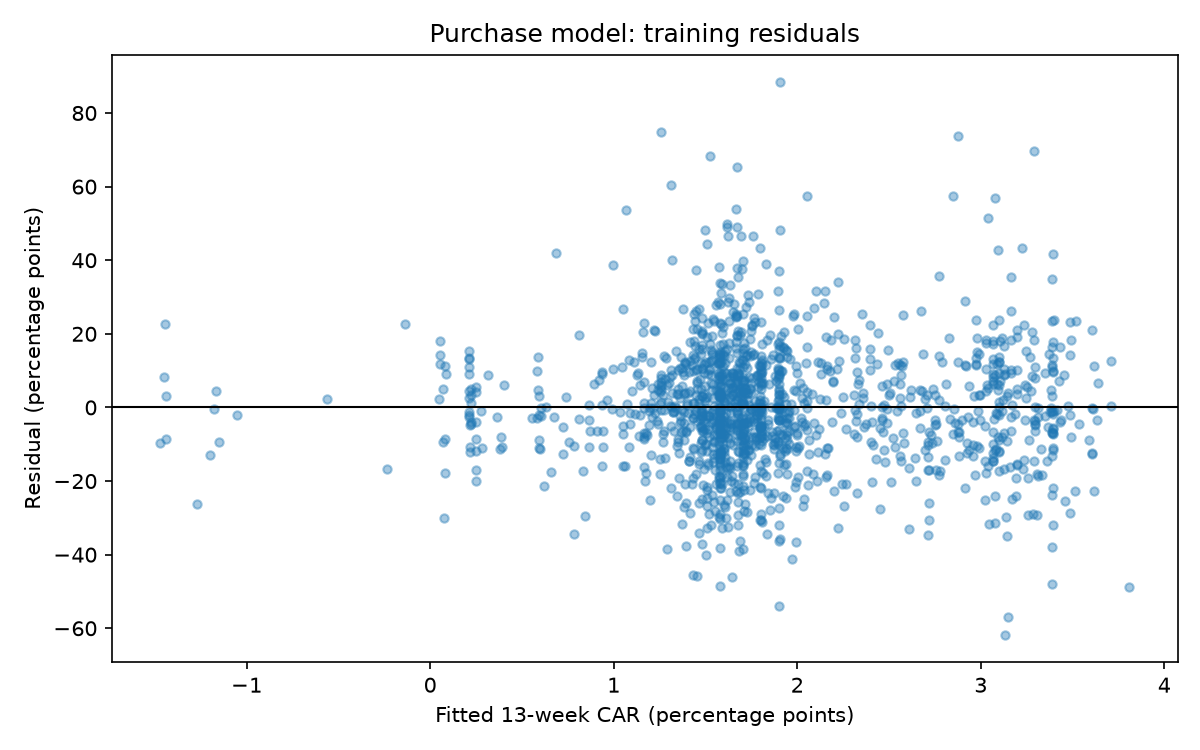

,training_residual_pp
count,1.425000e+03
mean,2.393407e-16
std,1.645359e+01
min,-6.172941e+01
1%,-3.823355e+01
50%,-6.840061e-01
99%,4.903325e+01
max,8.838642e+01


In [13]:
# Plot training residuals against fitted outcomes without using test outcomes for model selection.
training_fitted = prediction_model.predict(train[predictors]) * 100
training_residual = train["car_13w"].to_numpy() * 100 - training_fitted
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(training_fitted, training_residual, s=16, alpha=0.4)
ax.axhline(0, color="black", linewidth=1)
ax.set(xlabel="Fitted 13-week CAR (percentage points)", ylabel="Residual (percentage points)",
       title="Purchase model: training residuals")
fig.tight_layout()
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=150)
display(Image(data=buffer.getvalue()))
plt.close(fig)
display(pd.Series(training_residual).describe(percentiles=[0.01, 0.5, 0.99]).rename("training_residual_pp").to_frame())

**Residual interpretation:** Predicted CARs occupy a narrow range, while training residuals run from about **-61.73 to +88.39 percentage points**. The middle 98% lies roughly between -38.23 and +49.03 points. The model misses much of the variation among purchases, consistent with its limited advantage over the baseline. The uneven spread also cautions against assuming constant error variance.

## 10. How Certain Are the Associations?

The later-period test shows limited forecasting value, but a different issue remains: how much uncertainty surrounds the average purchase comparisons and the role and size associations? We assess that question separately using a reduced sample.

### 10.1 A Smaller Sample for Assessing Uncertainty

Events from the same company can share weeks in their 13-week outcomes. Treating those events as independent can make intervals too narrow. To use the row bootstrap covered in class, we select **one earliest eligible non-mixed event per company**. We apply this rule separately to the purchase-versus-sale comparison and the purchase-only model, using dates and eligibility.

A **bootstrap** repeatedly samples the selected rows with replacement and recalculates the estimates. The intervals apply to these reduced samples and assume the selected companies are sufficiently independent and representative of the population being studied. Companies can still respond to shared market and industry shocks, even after adjusting returns for SPY. That matters here because 82.9% of the reduced comparison sample comes from 2020 (Section 10.2). Shared shocks can make the intervals too narrow even with the adjustment for multiple tests.

A follow-up analysis could resample companies with replacement and keep all eligible events from each selected company together. This would let us assess uncertainty for the full eligible event sample.

#### Four Claims and the Decision Rule

| Claim | Quantity in the reduced sample |
|---|---|
| Purchase mean | Mean 13-week CAR among purchases in the earliest-event comparison sample |
| Purchase minus sale | Difference between purchase and sale means in that sample |
| C-suite coefficient | Adjusted executive-participation coefficient among earliest eligible purchases |
| Log-value coefficient | Adjusted purchase-size coefficient among earliest eligible purchases |

For each claim, the **null hypothesis** is that the quantity equals zero. We use two-sided intervals and separately check whether an estimate points in the hypothesized positive direction. The first research hypothesis requires both purchase-related claims; the role and size claims are evaluated separately.

Checking four claims creates more opportunities for a false positive. The **Bonferroni adjustment** divides a 0.05 family error target by four, assigning 0.0125 to each claim. We therefore use **98.75% percentile intervals**, from the 0.625th to the 99.375th bootstrap percentiles, for decisions. An interval excluding zero rejects that zero null under the stated assumptions; otherwise we fail to reject it. Ordinary 95% intervals are shown for comparison.

We use 10,000 draws with seeds 2950 and 2951 for the comparison and purchase models, respectively. Each draw retains the original sample size and all outcome-predictor pairings. Percentile coverage is approximate. The earlier model results were already visible when this uncertainty design was chosen, as disclosed in Section 5.

### 10.2 Selecting the Inference Samples

We take the earliest eligible non-mixed event per company from each relevant sample. The checks below confirm that no company appears twice. We then report the sample sizes, purchase/sale balance, C-suite balance, and event-year composition so that the reduced scope is visible.

In [14]:
# Select one earliest non-mixed event per company without using outcome values in selection.
inference_comparison = (samples_1["No mixed weeks"].sort_values(["issuer_cik", "event_week"])
                        .drop_duplicates("issuer_cik", keep="first").copy())
inference_purchases = (samples_2["No mixed weeks"].sort_values(["issuer_cik", "event_week"])
                       .drop_duplicates("issuer_cik", keep="first").copy())
for frame in [inference_comparison, inference_purchases]:
    assert frame["issuer_cik"].is_unique
    assert frame["mixed_week"].eq(0).all()
    assert frame["car_13w"].notna().all()
assert inference_purchases["trans_code"].eq("P").all()
assert set(inference_comparison["trans_code"]) == {"P", "S"}
assert set(inference_purchases["any_c_suite"]) == {0, 1}
inference_counts = pd.DataFrame([
    {"sample": name, "events_and_companies": len(frame),
     "purchases": int(frame["trans_code"].eq("P").sum()),
     "sales": int(frame["trans_code"].eq("S").sum()),
     "c_suite_events": int(frame["any_c_suite"].eq(1).sum())}
    for name, frame in [("Earliest event", inference_comparison), ("Earliest purchase", inference_purchases)]])
display(inference_counts)
inference_years = pd.concat({"Earliest event": inference_comparison["event_week"].dt.year.value_counts(),
                            "Earliest purchase": inference_purchases["event_week"].dt.year.value_counts()}, axis=1).fillna(0).astype(int).sort_index()
inference_years.index.name = "event_year"
display(inference_years)
reduced_purchase_fit = LinearRegression().fit(inference_purchases[predictors], inference_purchases["car_13w"])
comparison_purchase = inference_comparison.loc[inference_comparison["trans_code"].eq("P"), "car_13w"].mean()
comparison_sale = inference_comparison.loc[inference_comparison["trans_code"].eq("S"), "car_13w"].mean()
claim_names = ["Purchase mean", "Purchase minus sale", "C-suite coefficient", "Log-value coefficient"]
reduced_estimates = np.array([comparison_purchase, comparison_purchase - comparison_sale,
                              reduced_purchase_fit.coef_[0], reduced_purchase_fit.coef_[1]])
scope_comparison = pd.DataFrame({"claim": claim_names,
    "original_full_event_estimate_pp": [model1_results.iloc[0]["purchase_mean_pp"],
        model1_results.iloc[0]["purchase_minus_sale_pp"], model2_results.iloc[0]["c_suite_pp"],
        model2_results.iloc[0]["log_value_pp"]],
    "reduced_sample_estimate_pp": reduced_estimates * 100})
display(scope_comparison.round(4))

,sample,events_and_companies,purchases,sales,c_suite_events
0,Earliest event,537,101,436,196
1,Earliest purchase,380,380,0,87


,Earliest event,Earliest purchase
event_year,,
2020,445,189
2021,24,48
2022,15,56
2023,14,34
2024,19,21
2025,20,32


,claim,original_full_event_estimate_pp,reduced_sample_estimate_pp
0,Purchase mean,2.1257,6.7295
1,Purchase minus sale,4.5972,9.7973
2,C-suite coefficient,2.1766,3.1472
3,Log-value coefficient,0.1784,0.1934


**Sample composition:** The comparison now contains **537 companies: 101 purchases and 436 sales**. The purchase-only sample contains **380 companies**, including 87 C-suite events. The earliest-event rule puts **445 comparison events (82.9%) in 2020**, compared with 189 (49.7%) in the purchase-only sample.

The selection also changes the estimates: the reduced-sample purchase mean is **6.73 points** and the purchase-minus-sale gap is **9.80**, versus 2.13 and 4.60 in the full sample. The reduced C-suite and log-value coefficients are 3.15 and 0.193 points, versus 2.18 and 0.178. The following intervals belong to these reduced estimates only.

### 10.3 Bootstrap Confidence Intervals

For the comparison sample, each draw resamples complete company-event rows and calculates both the purchase mean and the purchase-minus-sale gap. For the purchase model, it resamples complete rows and refits the same three-predictor regression. Keeping each outcome with its predictors preserves their observed relationship.

The checks stop if a draw lacks a comparison group or cannot identify all regression coefficients. Valid extreme observations remain included.

In [15]:
# Bootstrap whole rows with fixed seeds and compute ordinary and Bonferroni-adjusted percentile intervals.
BOOTSTRAP_DRAWS = 10000
FAMILY_ALPHA = 0.05
FAMILY_SIZE = 4
bootstrap_estimates = np.empty((BOOTSTRAP_DRAWS, FAMILY_SIZE))
rng_comparison = np.random.default_rng(2950)
rng_purchases = np.random.default_rng(2951)
comparison_y = inference_comparison["car_13w"].to_numpy()
comparison_p = inference_comparison["trans_code"].eq("P").to_numpy()
purchase_x = inference_purchases[predictors].to_numpy(dtype=float)
purchase_y = inference_purchases["car_13w"].to_numpy()
assert np.linalg.matrix_rank(np.column_stack([np.ones(len(purchase_x)), purchase_x])) == 4

for draw in range(BOOTSTRAP_DRAWS):
    index_1 = rng_comparison.choice(len(comparison_y), size=len(comparison_y), replace=True)
    sampled_y, sampled_p = comparison_y[index_1], comparison_p[index_1]
    assert sampled_p.any() and (~sampled_p).any(), "A resample lacks a comparison group."
    mean_p, mean_s = sampled_y[sampled_p].mean(), sampled_y[~sampled_p].mean()
    bootstrap_estimates[draw, :2] = [mean_p, mean_p - mean_s]

    index_2 = rng_purchases.choice(len(purchase_y), size=len(purchase_y), replace=True)
    sampled_x = purchase_x[index_2]
    assert np.linalg.matrix_rank(np.column_stack([np.ones(len(sampled_x)), sampled_x])) == 4
    sampled_fit = LinearRegression().fit(sampled_x, purchase_y[index_2])
    bootstrap_estimates[draw, 2:] = sampled_fit.coef_[:2]

assert np.isfinite(bootstrap_estimates).all()
ordinary_limits = np.percentile(bootstrap_estimates, [2.5, 97.5], axis=0) * 100
tail_percent = 100 * FAMILY_ALPHA / FAMILY_SIZE / 2
adjusted_limits = np.percentile(bootstrap_estimates, [tail_percent, 100 - tail_percent], axis=0) * 100
uncertainty_results = pd.DataFrame({"claim": claim_names, "estimate_pp": reduced_estimates * 100,
    "CI95_low_pp": ordinary_limits[0], "CI95_high_pp": ordinary_limits[1],
    "CI98.75_low_pp": adjusted_limits[0], "CI98.75_high_pp": adjusted_limits[1]})
uncertainty_results["conditional_decision"] = np.where(
    (adjusted_limits[0] > 0) | (adjusted_limits[1] < 0), "Reject zero", "Fail to reject zero")
uncertainty_results["direction"] = np.where(adjusted_limits[0] > 0, "Positive interval",
    np.where(adjusted_limits[1] < 0, "Negative interval", "Includes zero"))
print(f"Completed {BOOTSTRAP_DRAWS:,} draws per sample. All resamples passed group/design checks.")
print(f"Four-claim error allocation: {FAMILY_ALPHA / FAMILY_SIZE:.4f}; adjusted percentiles: {tail_percent:.3f}, {100-tail_percent:.3f}.")
print("All intervals below concern the reduced samples and assume sufficiently independent companies.")
display(uncertainty_results.round(4))

Completed 10,000 draws per sample. All resamples passed group/design checks.
Four-claim error allocation: 0.0125; adjusted percentiles: 0.625, 99.375.
All intervals below concern the reduced samples and assume sufficiently independent companies.


,claim,estimate_pp,CI95_low_pp,CI95_high_pp,CI98.75_low_pp,CI98.75_high_pp,conditional_decision,direction
0,Purchase mean,6.7295,2.4470,11.1383,1.1892,12.4522,Reject zero,Positive interval
1,Purchase minus sale,9.7973,5.1965,14.5965,3.8596,15.8870,Reject zero,Positive interval
2,C-suite coefficient,3.1472,-2.0266,8.0983,-3.7175,9.6068,Fail to reject zero,Includes zero
3,Log-value coefficient,0.1934,-0.6686,0.9892,-0.9009,1.2214,Fail to reject zero,Includes zero


**Results under the stated assumptions:**

| Claim | Estimate (percentage points) | Adjusted 98.75% interval | Decision about zero |
|---|---:|---|---|
| Purchase mean | 6.73 | [1.19, 12.45] | Reject; positive interval |
| Purchase minus sale | 9.80 | [3.86, 15.89] | Reject; positive interval |
| C-suite coefficient | 3.15 | [-3.72, 9.61] | Fail to reject |
| Log-value coefficient, per log unit | 0.193 | [-0.901, 1.221] | Fail to reject |

The reduced-sample purchase comparisons meet the positive-direction criterion. For role and size, the intervals allow both positive and negative associations: their positive estimates alone are insufficient evidence against zero. Failure to reject does not establish that an association is absent.

These decisions are conditional on the assumptions in Section 10.1.

### 10.4 Reading the Intervals

The narrow bars show ordinary 95% bootstrap intervals. The wider bars show the 98.75% intervals used for the four-claim decision rule. The vertical line marks zero. These are intervals for different quantities with their units specified in the labels; the widths should not be used to rank predictor importance. Crossing zero means the corresponding zero null is not rejected by this conditional procedure.

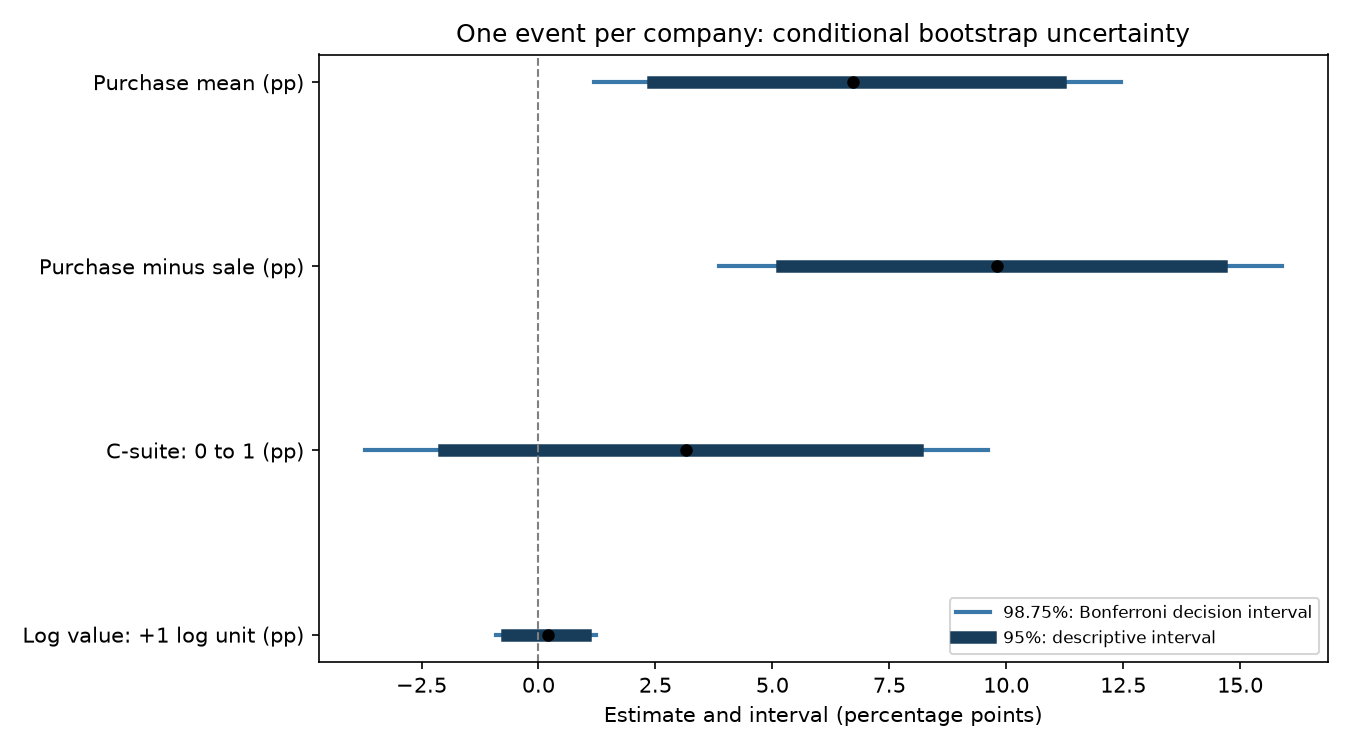

In [16]:
# Display the reduced-sample confidence intervals with the adjusted decision threshold clearly identified.
labels = ["Purchase mean (pp)", "Purchase minus sale (pp)",
          "C-suite: 0 to 1 (pp)", "Log value: +1 log unit (pp)"]
fig, ax = plt.subplots(figsize=(9, 5))
for i in range(FAMILY_SIZE):
    ax.plot(adjusted_limits[:, i], [i, i], color="#3978a8", linewidth=2,
            label="98.75%: Bonferroni decision interval" if i == 0 else None)
    ax.plot(ordinary_limits[:, i], [i, i], color="#173d5a", linewidth=6,
            label="95%: descriptive interval" if i == 0 else None)
    ax.scatter(reduced_estimates[i] * 100, i, color="black", s=25, zorder=3)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_yticks(range(FAMILY_SIZE), labels)
ax.invert_yaxis()
ax.set_xlabel("Estimate and interval (percentage points)")
ax.set_title("One event per company: conditional bootstrap uncertainty")
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
uncertainty_buffer = BytesIO()
fig.savefig(uncertainty_buffer, format="png", dpi=150)
display(Image(data=uncertainty_buffer.getvalue()))
plt.close(fig)

## 11. Limitations and Responsible Interpretation

### 11.1 Dependence and Sample Selection

The main models weight events equally, giving companies with frequent disclosures more influence. The uncertainty check uses each company’s earliest eligible event in the relevant sample. Section 10.1 explains how this affects the scope of the intervals.

The sample is also selected by historical index membership and available prices. Missing prices or insufficient histories exclude **1,720 events**; delisted or reorganized firms may differ systematically from retained firms. Historical membership reduces reliance on today's constituents but does not eliminate errors in community-maintained membership or ticker matching. The direction of the resulting selection bias is unknown.

### 11.2 Measurement and Alternative Explanations

Titles, joint filings, and amendment handling can affect assigned roles, insider counts, and retained trades. Weekly aggregation combines transactions with different motivations. Missing plan flags cannot establish that trades were discretionary.

The Friday entry rule approximates disclosure timing without exact publication timestamps or exchange-holiday handling. Available weekly observations can span more than 13 calendar weeks, and a stock's relationship with SPY can change after estimation. The four-week diagnostic includes the event week, so it is not strictly pre-disclosure.

Earnings, sector conditions, and other news can influence both trading and later returns. The models cannot separate all these explanations or establish that insider purchases caused subsequent performance. The later-period test includes some companies also seen in training, so it evaluates later events in this population rather than entirely new firms.

### 11.3 Potential Harms

CAR is a sum of model-adjusted weekly returns, not an executable portfolio profit. Transaction costs, taxes, and implementation delays are absent. Treating an average historical gap as a trading recommendation could expose readers to losses, particularly given the weak prediction results.

Public disclosures are also not evidence of illegal trading. Individual rankings or allegations could cause reputational harm. The analysis uses aggregated company events; interim owner identifiers remain linkable to people, and public filing does not imply consent to every research use.

## 12. Conclusions, Implications, and Next Steps

### 12.1 What the Evidence Means

This study examined whether publicly disclosed insider transactions contain information about subsequent stock performance. We combined SEC purchase and sale filings from 2020 through 2025 with historical S&P 500 membership and stock prices. The analysis asked two related questions: whether purchases were followed by stronger returns than sales, and whether executive participation and purchase size helped explain or predict outcomes among purchases. We measured performance using 13-week cumulative abnormal return (CAR), the sum of a stock's weekly returns above or below what its earlier relationship with the market would predict.

**Purchases and sales showed different average outcomes:** Among 2,227 purchase events, average 13-week CAR was **+2.13 percentage points**. Among 23,873 sale events, it was **-2.47 points**, giving a **4.60-point purchase-minus-sale difference**. Both parts of the first hypothesis matched the observed direction: the purchase mean was positive and exceeded the sale mean. The difference also remained positive after excluding weeks with both buying and selling and after removing overlapping return periods within companies. The pattern therefore was not limited to the original sample definition, although these checks do not establish that purchases caused better performance.

**Executive involvement and purchase size had positive associations:** Within the full purchase sample, events involving a C-suite executive had fitted CARs **2.18 percentage points higher**, holding purchase value and insider count constant. Larger purchases also had a positive association, but its magnitude was small: a 1% increase in purchase dollars corresponded to about **0.0018 percentage points** higher fitted CAR. These estimates describe average relationships within the observed data. They do not show that every executive purchase performed well or that increasing a purchase would improve the stock's return.

**The uncertainty check provided narrower support:** In separate samples containing one eligible event per company, the adjusted confidence intervals were above zero for the purchase mean and purchase-minus-sale difference, but included zero for the executive and purchase-size coefficients. This provides conditional support for the first hypothesis in those smaller samples, while leaving the role and size relationships uncertain. Section 10.1 explains the assumptions behind these sample-specific results.

**Predicting individual outcomes remained difficult:** We fitted the purchase model to earlier events and evaluated it on 690 later purchase events. Its root mean squared error, a measure of prediction error that gives greater weight to large misses, was **19.454 percentage points**, compared with **19.509 points** for always predicting the earlier purchase mean. The improvement was just **0.055 points**, or about **0.28%** of the baseline error. Executive participation, purchase size, and insider count therefore added little forecasting value on this test, despite their observed historical associations.

Taken together, the findings show why an average pattern and a useful investment forecast are different results. Purchase disclosures were followed by stronger average market-adjusted performance than sales, but the selected purchase characteristics did little to identify how a particular later event would perform. For someone researching a company, disclosures may provide context for further investigation alongside business fundamentals and contemporaneous news. This study does not demonstrate a profitable strategy for following insider trades: an executable strategy, its costs, and its performance on fresh data would still need to be evaluated.

### 12.2 What Would Strengthen the Evidence?

The following are proposed extensions, not analyses completed in this report:

1. **Assess stability across calendar periods:** Prespecify comparisons across years and examine whether the purchase-versus-sale pattern is concentrated in unusual market conditions. An uncertainty design that accounts for shared company and calendar shocks would be needed before stronger full-sample significance claims.
2. **Improve coverage and timing:** Recover missing price histories where possible and validate filing timestamps, holidays, and ticker continuity. This would clarify whether exclusions and the weekly entry approximation drive part of the observed gap.
3. **Evaluate practical usefulness on new data:** Specify any model changes using training data, then evaluate them on a fresh period that has not already been inspected. A trading interpretation would additionally require explicit entry and exit rules, portfolio construction, and costs.

The evidence supports continued investigation of public purchase disclosures. Its present contribution is a reproducible average pattern and a clear demonstration of how little the selected purchase characteristics improve later-event forecasts.

## 13. Acknowledgements

This study uses SEC insider transaction data, historical S&P 500 membership records, Yahoo Finance price data accessed through yfinance, and Python scientific-computing libraries for data preparation, analysis, and visualization. This research was completed at Cornell University with Saif Mahmud as mentor. The authors are Vansh Kakra (vk365), Dev Shukla (ds2395), and Wilson Wang (ww576).

OpenAI ChatGPT/Codex assisted with code implementation, explanation drafting, execution checks, and report preparation, including editorial revisions. Numerical results were computed from the saved project data. The authors remain responsible for the analysis, its assumptions, and the final text.

## 14. Bibliography

Cohen, L., Malloy, C., & Pomorski, L. (2012). Decoding inside information. *The Journal of Finance, 67*(3), 1009-1043. https://doi.org/10.1111/j.1540-6261.2012.01740.x. See also the authors' [Harvard Law School Forum summary](https://corpgov.law.harvard.edu/2012/02/03/decoding-inside-information/).

Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daume III, H., & Crawford, K. (2018). *Datasheets for datasets* [Preprint]. arXiv. https://arxiv.org/abs/1803.09010v1

Jeng, L. A., Metrick, A., & Zeckhauser, R. (2003). Estimating the returns to insider trading: A performance-evaluation perspective. *The Review of Economics and Statistics, 85*(2), 453-471. [Author's publication page](https://rzeckhauser.scholars.harvard.edu/publications/estimating-returns-insider-trading-performance-evaluation-perspective).

Lakonishok, J., & Lee, I. (2001). Are insider trades informative? *The Review of Financial Studies, 14*(1), 79-111. https://doi.org/10.1093/rfs/14.1.79

Seyhun, H. N. (1986). Insiders' profits, costs of trading, and market efficiency. *Journal of Financial Economics, 16*(2), 189-212. https://doi.org/10.1016/0304-405X(86)90060-7

U.S. Securities and Exchange Commission. (n.d.). *Insider transactions data sets*. Quarterly files covering 2020-2025. https://www.sec.gov/data-research/sec-markets-data/insider-transactions-data-sets

U.S. Securities and Exchange Commission. (n.d.). *Investor bulletin: Insider transactions and Forms 3, 4, and 5*. https://www.sec.gov/files/forms-3-4-5.pdf

U.S. Securities and Exchange Commission. (2023, January 20). *Modernizing Rule 10b5-1 insider trading plans*. https://www.sec.gov/newsroom/modernizing-rule-10b5-1-insider-trading-plans

fja05680 and contributors. (n.d.). *Current and historical lists of S&P 500 components since 1996* [Data repository]. GitHub. https://github.com/fja05680/sp500

Yahoo Finance. (n.d.). *Historical stock prices* [Data]. Saved Phase 2 price snapshot collected through October 19, 2026. https://finance.yahoo.com/

yfinance contributors. (n.d.). *yfinance.download* [Software documentation]. https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html

Cornell University, INFO 2950 course staff. (2026). *Lectures 14-17* [Course slides, October 20, October 22, October 27, and November 3]. Uploaded course materials. In particular, Lecture 15, slides 186-193, covers bootstrap percentile intervals; Lecture 17, slide 45, connects confidence intervals to testing and slides 107-108 discuss Bonferroni adjustment.

Cornell University, INFO 2950 course staff. (2026). *Phase III and IV rubric, Fall 2026* [Course handout]. Uploaded course material.

NumPy developers. (n.d.). *NumPy documentation* [Software documentation]. https://numpy.org/doc/

pandas development team. (n.d.). *pandas documentation* [Software documentation]. https://pandas.pydata.org/docs/

scikit-learn developers. (n.d.). *scikit-learn user guide* [Software documentation]. https://scikit-learn.org/stable/user_guide.html

Matplotlib development team. (n.d.). *Matplotlib documentation* [Software documentation]. https://matplotlib.org/stable/

Project Jupyter and IPython contributors. (n.d.). *Jupyter and IPython* [Notebook and execution software]. https://jupyter.org/ and https://ipython.org/

OpenAI. (2026). *ChatGPT/Codex* [AI assistance with code and writing, described in Section 13]. https://openai.com/

## Appendix A. Original Research Plans

The two preregistration statements below preserve the original wording, including references to the earlier project stage and methods that were subsequently changed. Only heading levels and numbering have been reformatted for this appendix. They are an audit record, not a description of every method ultimately used. Section 5 explains the chronological split and added sensitivity checks; Section 10 documents the later uncertainty analysis.

### A.1 Preregistration Statement 1

#### Purchases and Subsequent Returns

**Prior analysis:** Both plans were written after the EDA showed separate purchase and sale return distributions, but before fitting the research models or comparing returns by role or purchase size. These are not outcome-blind plans. Any later changes will be identified in the final report.

**Hypothesis:** The average **13-week CAR after purchase events is positive and exceeds the average after sale events**. The primary horizon is 13 weeks; 1, 4, and 26 weeks provide secondary descriptive context.

**Motivation:** [Lakonishok and Lee (2001), *Are Insider Trades Informative?*](https://www.nber.org/papers/w6656) find purchases more informative than sales, with important firm-size differences. [Jeng, Metrick, and Zeckhauser (2003), *Estimating the Returns to Insider Trading: A Performance-Evaluation Perspective*](https://rzeckhauser.scholars.harvard.edu/publications/estimating-returns-insider-trading-performance-evaluation-perspective) report abnormal performance for purchase portfolios but not comparable evidence for sale portfolios. These findings motivate a directional hypothesis; their samples, weighting, and transaction timing differ from our public-disclosure event design and do not guarantee the result here.

#### Sample

The unit is one **company-week-direction event**, equally weighted regardless of its dollar value. Eligible filings are retained Form 4/4-A P/S records from 2020-2025 at companies matched to S&P 500 membership on the filing date. P/S is the operational purchase/sale definition and can include private transactions. Entry uses the **first Friday close on or after filing date plus one business day**, as implemented by a weekday offset; holiday and filing-time limitations are documented above.

The market model estimates alpha and beta using up to **52 available weekly returns strictly before the event week**, requiring at least **40**. Weekly abnormal return is actual stock return minus the model prediction (alpha plus beta times SPY return), written as `actual - (alpha + beta * market_return)`. `car_13w` sums the next 13 weekly abnormal returns, excluding the event week. It is stored in decimal units.

Use events with observed `car_13w` and a P/S direction. The current eligible sample is **26,100 events: 2,227 purchases and 23,873 sales**. Exclude missing price histories, insufficient estimation history, and missing outcomes; do not impute zero returns. Keep `mixed_week = 1` events in the primary analysis. Do not trim or winsorize valid outcomes based on their value. Report the retained counts and exclusions.

#### Planned Analysis

Fit ordinary least squares with an intercept using `sklearn.linear_model.LinearRegression`:

`car_13w = intercept + beta_purchase * is_purchase + error`

`is_purchase` is 1 for P and 0 for S, so **sales are the reference group**. The intercept estimates average sale CAR; `beta_purchase` estimates the purchase-minus-sale difference. The implied purchase mean is `intercept + beta_purchase`. The hypothesis predicts **both `beta_purchase > 0` and `intercept + beta_purchase > 0`**. Both conditions are needed to support the hypothesis.

Report both group means, the coefficient and implied purchase mean in percentage points, and purchase-only mean CARs at 1, 4, 13, and 26 weeks with their available counts. A decimal coefficient of 0.01 represents a one-percentage-point difference. **We will assess coefficient direction and size, without p-values or statistical-significance claims.** In particular, repeated events and overlapping windows do not justify treating every row as independent evidence.

**Sensitivity analysis:** Repeat the same 13-week model after excluding `mixed_week = 1` events, reporting the new counts and coefficient alongside the primary result. This sensitivity check does not fix other window overlap. Report positive, zero, negative, and inconsistent results, regardless of whether they support the hypothesis. A null or opposite sign will not trigger a switch of the primary horizon. Further specifications will be labeled exploratory.

### A.2 Preregistration Statement 2

#### Insider Role and Purchase Size

**Hypothesis:** Among purchase events, **C-suite participation and larger dollar purchase values are associated with higher 13-week CARs**, controlling for the number of recorded insiders.

**Motivation:** Executives may have broad access to company information, and committing more dollars may indicate stronger conviction, although wealth and liquidity can also explain purchase size. [Seyhun (1986), *Insiders' Profits, Costs of Trading, and Market Efficiency*](https://doi.org/10.1016/0304-405X(86)90060-7) motivates examining differences in information by insider position. [Cohen, Malloy, and Pomorski (2012), *Decoding Inside Information*](https://corpgov.law.harvard.edu/2012/02/03/decoding-inside-information/) distinguish routine trading from more informative trading. Their classification is not equivalent to our C-suite flag or 10b5-1 checkbox. The literature motivates heterogeneity, not certainty that our exact role proxy or larger nominal purchases will predict better outcomes. Jeng, Metrick, and Zeckhauser (2003) also find that top executives do not outperform other insiders in their setting, so the role hypothesis faces meaningful contrary evidence.

#### Sample and Model

Use **purchase events only** (`trans_code = P`) with observed `car_13w`, `any_c_suite`, `log_value`, and `n_insiders`, currently **2,227 events**. Apply Statement 1's filing scope, event unit, entry rule, market model, and return definition. Exclude missing required values without imputation and report exclusions. Keep valid extreme values and mixed weeks in the primary model. Each event receives equal weight.

`any_c_suite` equals 1 when an event includes a trade assigned C-suite rank: an officer title matching CEO, CFO, COO, their expanded names, or President excluding Vice President. Zero includes directors, other officers, 10% owners, and Other; it is **not a directors-only reference group**. `log_value` is the natural logarithm of total reported purchase dollars. `n_insiders` counts distinct retained owner CIKs. Joint-filing and title limitations apply.

Fit the following multivariable linear regression with an intercept using `LinearRegression`:

`car_13w = intercept + beta_c_suite * any_c_suite + beta_log_value * log_value + beta_insiders * n_insiders + error`

The directional predictions are **`beta_c_suite > 0` and `beta_log_value > 0`**. Report the two predictions separately; support for one does not imply support for both. The C-suite coefficient is an adjusted difference in decimal CAR at the same recorded log value and insider count. For a 1% larger purchase, the exact modeled difference is `beta_log_value * log(1.01)`, approximately `0.01 * beta_log_value` in decimal CAR, holding other predictors fixed. Multiply by 100 to express percentage points. These are associations, not causal effects. No interactions, extra controls, or outcome-driven variable selection are included in the primary specification.

#### Model Checks and Reporting

1. **Collinearity:** Report predictor Pearson/Spearman correlations and variance inflation factors (VIF). Compute each VIF as `1 / (1 - R_squared)` from regressing one predictor on the others with an intercept. Large values indicate overlapping predictor information. Discuss the diagnostics without automatically dropping a prespecified variable to improve its coefficient.
2. **Prediction evaluation:** Make one random **70% training / 30% test split**, using `train_test_split(test_size=0.30, random_state=2950)`. Fit the fixed specification on the training subset only. Evaluate once on the held-out test subset with **RMSE**, the square root of mean squared prediction error, and compare with a baseline that always predicts the training outcome mean. Report RMSE in percentage points and both sample sizes. Examine a training residual-versus-fitted plot for systematic patterns and unequal spread; do not tune the model on test outcomes.
3. **Association estimates:** Fit the same fixed specification on all eligible purchase events for descriptive coefficients, explicitly distinguishing that full-sample fit from the model used for held-out RMSE. Report every coefficient, its units, and the sign of each prespecified directional prediction. No t-tests, p-values, or statistical-significance claims are planned.
4. **Dependence caveat and sensitivity:** A random event split can place the same company and overlapping outcome periods in both subsets. Test RMSE therefore measures this random-split task and is not an estimate of independent future-period performance. Repeat the fixed full-sample association model after excluding mixed weeks, and present it beside the primary model. A time-ordered or company-grouped validation scheme is a reviewer question for Phase 3, not an undisclosed replacement chosen after results.

**Later-period extension:** Leave `any_plan_10b5_1` out of the main model. A separately labeled exploratory Phase 3 analysis may consider 2023-2025 filings with observed flags, starting no earlier than April 1, 2023 and checking component-flag coverage. The small positive-flag purchase sample limits precision. 

We will report results regardless of whether they support the hypotheses and document any changes to the specified model.